# 04 · Ajuste de hiperparámetros (tuning)

Se ajustan los 3 mejores candidatos del notebook 03: **regresión logística**, **hist gradient boosting** y **random forest**. La red neuronal queda fuera (menor PR-AUC, la más lenta y sin converger).

**Método: `RandomizedSearchCV`, con 30 configuraciones por modelo.**
- La **búsqueda exhaustiva** (grid) prueba todas las combinaciones de una cuadrícula: con 4 o 5 hiperparámetros, el número de combinaciones crece muy rápido, y con solo 30 configuraciones la cuadrícula quedaría muy gruesa.
- La **búsqueda aleatoria** toma 30 combinaciones al azar del espacio: con el mismo presupuesto explora más valores distintos de cada hiperparámetro, y es la que se vio en clase.
- **Optuna** elige cada configuración según las anteriores y puede ser más eficiente, pero agrega una librería y complejidad que este presupuesto no necesita.

**Misma validación que en el notebook 03:** `GroupKFold` por crédito, 5 pliegues, PR-AUC. Cada configuración se registra en MLflow como **corrida hija** (*nested run*) dentro de una **corrida padre** por modelo.

**Criterio de mejora:** el modelo ajustado mejora solo si su PR-AUC en CV supera a la del modelo por defecto en más que la desviación entre pliegues. Si no, la diferencia puede deberse al azar de los pliegues.

## 1. Datos, experimento y resultados por defecto

In [1]:
import sys
sys.path.append("..")

import logging
import subprocess
import time
import warnings

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import pandas as pd
from mlflow.models import infer_signature
from scipy.optimize import OptimizeWarning
from scipy.stats import loguniform, randint
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from src.datos import TABLA, huella
from src.pipeline import (FIN_ENTRENAMIENTO, INICIO_PRUEBA,
                          cargar_y_dividir, construir_preparacion)

logging.getLogger("mlflow").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", module="mlflow")
warnings.filterwarnings("ignore", category=OptimizeWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message="The groups parameter is ignored")

X_ent, X_prueba, y_ent, y_prueba, grupos_ent = cargar_y_dividir()
huella_datos = huella(pd.concat([X_ent, y_ent], axis=1))
commit = subprocess.check_output(["git", "rev-parse", "--short", "HEAD"]).decode().strip()
mlflow.set_experiment("priorizacion-cartera")

# Resultados de los modelos por defecto, leídos del registro de MLflow (notebook 03)
defecto = mlflow.search_runs(experiment_names=["priorizacion-cartera"], filter_string="tags.fase = 'candidato'")
defecto = defecto.set_index("tags.mlflow.runName")[["metrics.pr_auc_cv_promedio", "metrics.pr_auc_cv_desviacion"]]

print("Huella de los datos:", huella_datos, "| Commit:", commit)
defecto.round(4)

Huella de los datos: 51a0dd5e8d2d | Commit: 5638b45


,metrics.pr_auc_cv_promedio,metrics.pr_auc_cv_desviacion
tags.mlflow.runName,,
llm few-shot,NaN,NaN
red neuronal,0.4021,0.0216
hist gradient boosting,0.4431,0.0272
random forest,0.4132,0.0220
regresion logistica,0.4453,0.0265


## 2. Espacios de búsqueda

| Modelo | Hiperparámetro | Rango | Escala | Por qué |
|---|---|---|---|---|
| Regresión logística | `C` | 0.001 a 100 | logarítmica | Es el inverso de la fuerza de regularización. Su efecto es multiplicativo: pasar de 0.01 a 0.1 importa tanto como de 1 a 10 |
| | `class_weight` | `None`, `"balanced"` | — | Hallazgo del EDA: target desbalanceado |
| Hist gradient boosting | `learning_rate` | 0.01 a 0.3 | logarítmica | Tamaño de cada paso del boosting; efecto multiplicativo |
| | `max_depth` | 3, 5, 7, sin límite | — | Árboles menos profundos = menos sobreajuste |
| | `min_samples_leaf` | 20 a 500 | lineal | Más filas por hoja = reglas más generales (regularización) |
| | `l2_regularization` | 0.0001 a 10 | logarítmica | Penalización de las hojas; efecto multiplicativo |
| | `class_weight` | `None`, `"balanced"` | — | Target desbalanceado |
| Random forest | `n_estimators` | 100 a 400 | lineal | Más árboles = predicción más estable (no aumenta el sobreajuste) |
| | `max_depth` | 5, 10, 15, 20, sin límite | — | Limitar la profundidad reduce la memorización (brecha de 0.59 por defecto) |
| | `min_samples_leaf` | 1 a 200 | lineal | Regularización: hojas con más filas |
| | `max_features` | `"sqrt"`, 0.3, 0.5 | — | Columnas por división: menos columnas = árboles más distintos entre sí |
| | `class_weight` | `None`, `"balanced"` | — | Target desbalanceado |

La escala logarítmica (`loguniform`) reparte las 30 configuraciones de forma pareja entre órdenes de magnitud (0.001, 0.01, 0.1, …); con escala lineal, casi todas caerían cerca del valor máximo.

In [2]:
ESPACIOS = {
    "regresion logistica": {
        "modelo__C": loguniform(1e-3, 1e2),
        "modelo__class_weight": [None, "balanced"],
    },
    "hist gradient boosting": {
        "modelo__learning_rate": loguniform(0.01, 0.3),
        "modelo__max_depth": [3, 5, 7, None],
        "modelo__min_samples_leaf": randint(20, 500),
        "modelo__l2_regularization": loguniform(1e-4, 10),
        "modelo__class_weight": [None, "balanced"],
    },
    "random forest": {
        "modelo__n_estimators": randint(100, 400),
        "modelo__max_depth": [5, 10, 15, 20, None],
        "modelo__min_samples_leaf": randint(1, 200),
        "modelo__max_features": ["sqrt", 0.3, 0.5],
        "modelo__class_weight": [None, "balanced"],
    },
}

## 3. Búsqueda y registro en MLflow

`ajustar()` hace, para cada modelo:
1. La búsqueda aleatoria con 30 configuraciones, con la misma preparación y la misma validación por crédito.
2. Una **corrida padre** (`tuning <modelo>`) con la mejor configuración, su PR-AUC en CV, la mejora frente al modelo por defecto y el pipeline final (reentrenado con todo el entrenamiento) como artefacto.
3. Una **corrida hija** por cada una de las 30 configuraciones, con sus hiperparámetros y métricas.

En el tuning, la PR-AUC de entrenamiento es el promedio en los pliegues de entrenamiento de la CV (`mean_train_score`).

In [3]:
CV = GroupKFold(n_splits=5)
resumenes = []


def limpiar(valor):
    """Convierte los vacíos de cv_results_ (None en el espacio de búsqueda) en el texto 'None'."""
    return "None" if pd.isna(valor) else valor


def ajustar(nombre, modelo, familia):
    pipeline = Pipeline([("preparar", construir_preparacion()), ("modelo", modelo)])
    busqueda = RandomizedSearchCV(pipeline, ESPACIOS[nombre], n_iter=30, cv=CV, scoring="average_precision",
                                  return_train_score=True, random_state=42, n_jobs=-1)

    with mlflow.start_run(run_name=f"tuning {nombre}"):
        mlflow.set_tags({"fase": "tuning", "familia": familia, "commit": commit})
        mlflow.log_params({"modelo": nombre, "busqueda": "RandomizedSearchCV", "configuraciones": 30,
                           "semilla": 42, "tabla_origen": TABLA, "fin_entrenamiento": FIN_ENTRENAMIENTO,
                           "inicio_prueba": INICIO_PRUEBA, "huella_datos": huella_datos,
                           "filas_entrenamiento": len(X_ent), "validacion": "GroupKFold(5) por credito"})

        inicio = time.perf_counter()
        busqueda.fit(X_ent, y_ent, groups=grupos_ent)
        segundos = time.perf_counter() - inicio

        res = pd.DataFrame(busqueda.cv_results_)
        res["brecha"] = res["mean_train_score"] - res["mean_test_score"]
        columnas_param = [c for c in res.columns if c.startswith("param_")]

        for i, fila in res.iterrows():
            with mlflow.start_run(run_name=f"{nombre} config {i + 1}", nested=True):
                mlflow.set_tags({"fase": "tuning", "familia": familia, "commit": commit})
                mlflow.log_params({c.replace("param_modelo__", ""): limpiar(fila[c]) for c in columnas_param})
                mlflow.log_metrics({"pr_auc_entrenamiento": fila["mean_train_score"],
                                    "pr_auc_cv_promedio": fila["mean_test_score"],
                                    "pr_auc_cv_desviacion": fila["std_test_score"],
                                    "brecha": fila["brecha"],
                                    "segundos_entrenamiento": fila["mean_fit_time"]})

        mejor = res.loc[busqueda.best_index_]
        cv_defecto = defecto.loc[nombre, "metrics.pr_auc_cv_promedio"]
        desv_defecto = defecto.loc[nombre, "metrics.pr_auc_cv_desviacion"]
        mejora = mejor["mean_test_score"] - cv_defecto

        mlflow.log_params({"mejor_" + k.replace("modelo__", ""): limpiar(v) for k, v in busqueda.best_params_.items()})
        metricas = {"pr_auc_entrenamiento": mejor["mean_train_score"],
                    "pr_auc_cv_promedio": mejor["mean_test_score"],
                    "pr_auc_cv_desviacion": mejor["std_test_score"],
                    "brecha": mejor["brecha"],
                    "mejora_vs_defecto": mejora,
                    "segundos_busqueda": segundos}
        for j in range(5):
            metricas[f"pr_auc_pliegue_{j + 1}"] = mejor[f"split{j}_test_score"]
        mlflow.log_metrics(metricas)

        modelo_final = busqueda.best_estimator_
        firma = infer_signature(X_ent.head(100), modelo_final.predict_proba(X_ent.head(100))[:, 1])
        mlflow.sklearn.log_model(modelo_final, "modelo", signature=firma, input_example=X_ent.head(5))

    resumenes.append({"modelo": nombre, "pr_auc_cv_defecto": cv_defecto, "desviacion_defecto": desv_defecto,
                      "pr_auc_cv_ajustado": mejor["mean_test_score"], "desviacion_ajustado": mejor["std_test_score"],
                      "mejora": mejora, "mejora_real": mejora > max(desv_defecto, mejor["std_test_score"]),
                      "brecha_ajustado": mejor["brecha"], "segundos_busqueda": segundos})
    print(f"{nombre}: CV por defecto {cv_defecto:.4f} -> ajustado {mejor['mean_test_score']:.4f} "
          f"± {mejor['std_test_score']:.4f} | brecha {mejor['brecha']:.4f} | {segundos:.0f} s")
    print("Mejor configuración:", {k.replace("modelo__", ""): v for k, v in busqueda.best_params_.items()})
    return res

## 4. Regresión logística

In [4]:
res_lr = ajustar("regresion logistica", LogisticRegression(max_iter=1000, random_state=42), familia="lineal regularizado")

/workspaces/pset3-modelo-cartera/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/workspaces/pset3-modelo-cartera/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/workspaces/pset3-modelo-cartera/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/workspaces/pset3-modelo-cartera/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/workspaces/pset3-modelo-cartera/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/workspaces/pset3-modelo-cartera/.venv/lib/python3.12/site-packages/sk

regresion logistica: CV por defecto 0.4453 -> ajustado 0.4453 ± 0.0256 | brecha 0.0080 | 21 s
Mejor configuración: {'C': np.float64(73.92266140516048), 'class_weight': None}


**Resultado:** el tuning no mejoró la regresión logística (0.4453 por defecto y 0.4453 ajustada). La mejor configuración tiene C = 74, es decir, muy poca regularización: el modelo no sobreajustaba (brecha de 0.006 por defecto), así que la regularización no tenía nada que corregir. Los valores por defecto ya eran adecuados.

## 5. Hist gradient boosting

In [5]:
res_hgb = ajustar("hist gradient boosting", HistGradientBoostingClassifier(random_state=42), familia="boosting")

hist gradient boosting: CV por defecto 0.4431 -> ajustado 0.4589 ± 0.0215 | brecha 0.0807 | 82 s
Mejor configuración: {'class_weight': 'balanced', 'l2_regularization': np.float64(0.000299951185298926), 'learning_rate': np.float64(0.03529746546288799), 'max_depth': 5, 'min_samples_leaf': 235}


**Resultado:** la PR-AUC en CV subió de 0.4431 a 0.4589 ± 0.0215, pero la mejora (+0.016) es menor que la desviación entre pliegues, así que **no se considera una mejora real**. Lo que sí cambió fue el sobreajuste: la brecha bajó de 0.418 a 0.081. La mejor configuración regulariza el modelo (profundidad máxima 5, mínimo 235 filas por hoja, learning rate de 0.035 y `class_weight="balanced"`): rinde igual en créditos nuevos, pero ya no memoriza el entrenamiento, por lo que es más confiable.

## 6. Random forest

Es la búsqueda más lenta: cada configuración entrena entre 100 y 400 árboles, 5 veces.

In [6]:
res_rf = ajustar("random forest", RandomForestClassifier(random_state=42), familia="bagging")

random forest: CV por defecto 0.4132 -> ajustado 0.4491 ± 0.0223 | brecha 0.2053 | 483 s
Mejor configuración: {'class_weight': 'balanced', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 28, 'n_estimators': 234}


**Resultado:** es el modelo que más mejoró: de 0.4132 a 0.4491 ± 0.0223. La mejora (+0.036) supera la desviación entre pliegues, así que **sí es una mejora real**. La brecha bajó de 0.587 a 0.205: limitar la profundidad (10) y exigir al menos 28 filas por hoja evitó que los árboles memorizaran cada crédito. Es la búsqueda más costosa (486 s).

## 7. Resumen: ¿cuánto mejoró cada modelo?

`mejora_real` es verdadero solo si la mejora supera la desviación entre pliegues (la mayor entre la del modelo por defecto y la del ajustado).

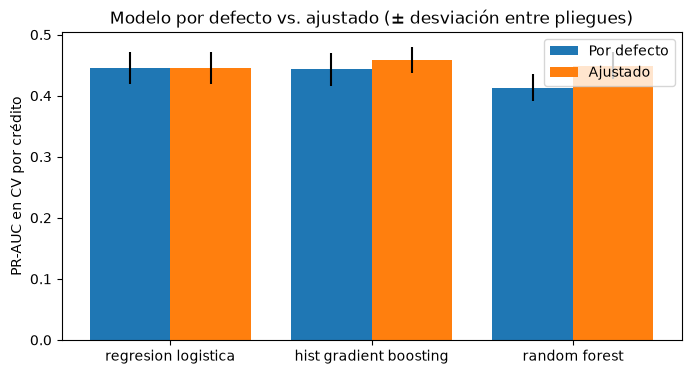

,modelo,pr_auc_cv_defecto,desviacion_defecto,pr_auc_cv_ajustado,desviacion_ajustado,mejora,mejora_real,brecha_ajustado,segundos_busqueda
0,regresion logistica,0.4453,0.0265,0.4453,0.0256,-0.0000,False,0.0080,20.6914
1,hist gradient boosting,0.4431,0.0272,0.4589,0.0215,0.0157,False,0.0807,81.5813
2,random forest,0.4132,0.0220,0.4491,0.0223,0.0359,True,0.2053,483.1220


In [7]:
tabla_tuning = pd.DataFrame(resumenes).round(4)

fig, eje = plt.subplots(figsize=(8, 4))
posiciones = range(len(tabla_tuning))
eje.bar([p - 0.2 for p in posiciones], tabla_tuning["pr_auc_cv_defecto"], width=0.4,
        yerr=tabla_tuning["desviacion_defecto"], label="Por defecto")
eje.bar([p + 0.2 for p in posiciones], tabla_tuning["pr_auc_cv_ajustado"], width=0.4,
        yerr=tabla_tuning["desviacion_ajustado"], label="Ajustado")
eje.set_xticks(list(posiciones))
eje.set_xticklabels(tabla_tuning["modelo"])
eje.set_ylabel("PR-AUC en CV por crédito")
eje.set_title("Modelo por defecto vs. ajustado (± desviación entre pliegues)")
eje.legend()
plt.savefig("../docs/figuras/tuning_mejora.png", bbox_inches="tight")
plt.show()

tabla_tuning

**Hallazgo: solo el random forest mejoró de verdad, y los tres modelos ajustados quedan prácticamente empatados.**
- **Evidencia:** random forest pasó de 0.413 a 0.449 (+0.036, mayor que la desviación de 0.022: mejora real). Hist gradient boosting pasó de 0.443 a 0.459 (+0.016, menor que la desviación de 0.027: no es mejora real). La regresión logística no cambió (0.445). Después del tuning, las diferencias entre los tres modelos (≈ 0.01) son menores que la desviación entre pliegues (≈ 0.02).
- **Consecuencia:** el ganador no se puede elegir solo por la PR-AUC en CV. En `05_seleccion` se comparan el mejor (hist gradient boosting ajustado) y el segundo (random forest ajustado) en el conjunto de prueba, con la métrica de negocio, el costo de entrenamiento y la explicabilidad. El tuning sí dejó modelos más confiables: la brecha bajó de 0.418 a 0.081 en boosting y de 0.587 a 0.205 en random forest.

## 8. Efecto de la regularización

Cada punto es una de las 30 configuraciones. Se grafica la PR-AUC en entrenamiento y en CV según el hiperparámetro que más regulariza cada modelo:
- **Regresión logística, `C`:** un C más chico es más regularización.
- **Boosting y random forest, `min_samples_leaf`:** más filas por hoja es más regularización.

Si la regularización funciona, al aumentarla la PR-AUC de entrenamiento baja (deja de memorizar) y la brecha con la CV se cierra.

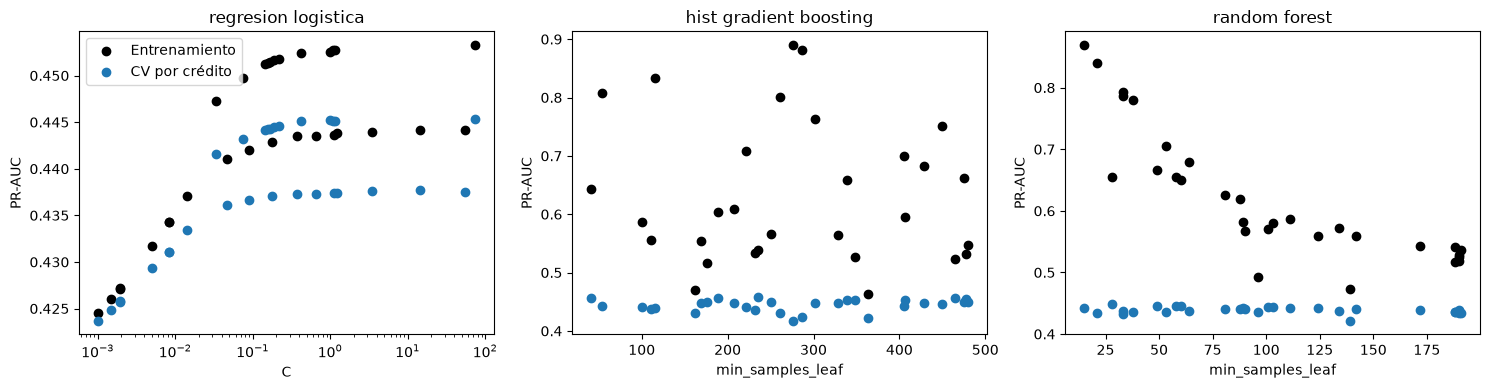

In [8]:
graficos = [("regresion logistica", res_lr, "param_modelo__C", True),
            ("hist gradient boosting", res_hgb, "param_modelo__min_samples_leaf", False),
            ("random forest", res_rf, "param_modelo__min_samples_leaf", False)]

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, (nombre, res, parametro, escala_log) in zip(ejes, graficos):
    x = res[parametro].astype(float)
    eje.scatter(x, res["mean_train_score"], color="black", label="Entrenamiento")
    eje.scatter(x, res["mean_test_score"], label="CV por crédito")
    if escala_log:
        eje.set_xscale("log")
    eje.set_title(nombre)
    eje.set_xlabel(parametro.replace("param_modelo__", ""))
    eje.set_ylabel("PR-AUC")
ejes[0].legend()
plt.tight_layout()
plt.savefig("../docs/figuras/tuning_regularizacion.png", bbox_inches="tight")
plt.show()

**Hallazgo: la regularización cierra la brecha sin perder rendimiento en créditos nuevos.**
- **Random forest:** al subir `min_samples_leaf` de 15 a 190, la PR-AUC de entrenamiento cae de 0.87 a 0.52, mientras la de CV se mantiene en ≈ 0.44. Es el efecto esperado de la regularización: el modelo deja de memorizar cada crédito y conserva lo que generaliza.
- **Hist gradient boosting:** el entrenamiento varía mucho entre configuraciones (0.47 a 0.89), pero la CV casi no cambia (0.42 a 0.46): el rendimiento extra en entrenamiento es memorización. La regularización depende de varios hiperparámetros a la vez (profundidad, `min_samples_leaf`, learning rate).
- **Regresión logística:** con C muy chico (mucha regularización) bajan el entrenamiento y la CV a la vez (subajuste); desde C ≈ 0.1 se estabilizan, con una brecha siempre mínima. Este modelo no sobreajustaba, así que regularizarlo más solo lo empeora.